In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

In [ ]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10

In [ ]:
file_path = 'indonesia_fintech_p2p_paylater_enriched_2026.csv'
df = pd.read_csv(file_path)

In [ ]:
print(f"Ukuran dataset awal: {df.shape}")

Ukuran dataset awal: (10000, 26)


In [ ]:
np.random.seed(42)
start_date = pd.to_datetime('2026-01-01')
end_date = pd.to_datetime('2026-10-31')
date_range = (end_date - start_date).days

random_days = np.random.randint(0, date_range, size=len(df))
df['application_date'] = start_date + pd.to_timedelta(random_days, unit='D')

In [ ]:
df['app_month'] = df['application_date'].dt.to_period('M').dt.to_timestamp()

In [ ]:
def assign_risk_tier(row):
    if row['twp90_default_status'] == 'Current-Performing' and row['financial_distress_index'] < 3.0:
        return 'Low Risk'
    elif row['twp90_default_status'] in ['Special-Mention-DPD1-30', 'Substandard-DPD31-60']:
        return 'Medium Risk'
    else:
        return 'High Risk / Default'

df['risk_tier'] = df.apply(assign_risk_tier, axis=1)

print(f"Data berhasil diproses. Total baris aktif: {len(df):,}\n")

Data berhasil diproses. Total baris aktif: 10,000



DATETIME LINE CHART

<Figure size 1200x600 with 0 Axes>

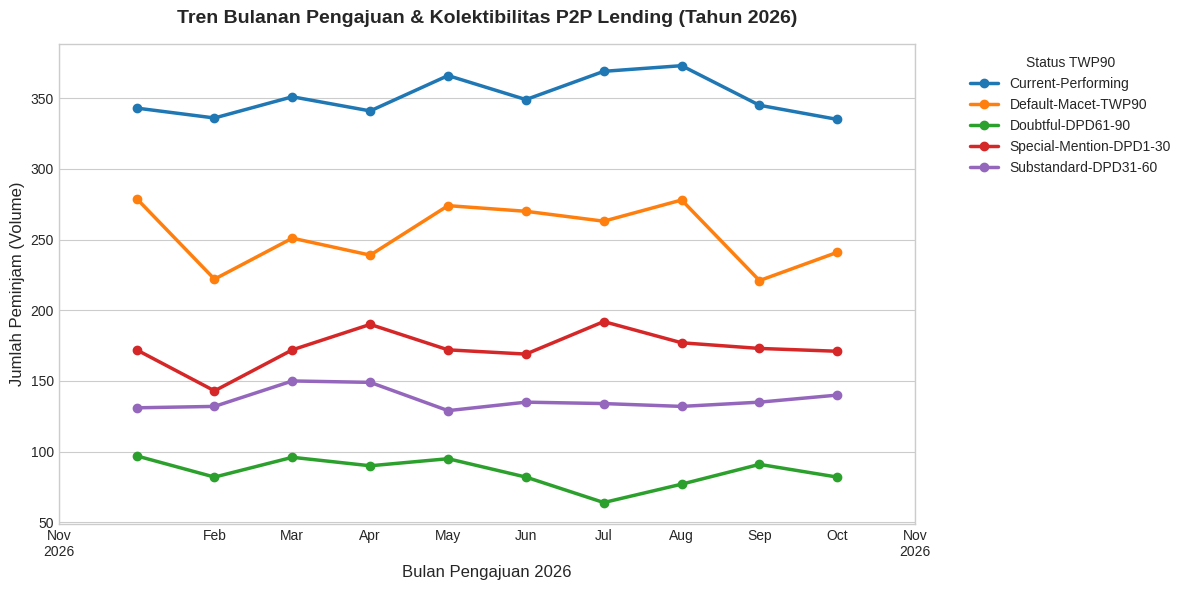

In [ ]:
plt.figure(figsize=(12, 6))
df_time_2026 = df.groupby(['app_month', 'twp90_default_status']).size().unstack(fill_value=0)

ax = df_time_2026.plot(kind='line', marker='o', linewidth=2.5, figsize=(12, 6))

ax.set_xlim(pd.to_datetime('2025-12-15'), pd.to_datetime('2026-11-15'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n2026'))

plt.title('Tren Bulanan Pengajuan & Kolektibilitas P2P Lending (Tahun 2026)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Bulan Pengajuan 2026', fontsize=12)
plt.ylabel('Jumlah Peminjam (Volume)', fontsize=12)
plt.legend(title='Status TWP90', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Analisis Sektor Pekerjaan vs Status DEfault

In [ ]:
df_filtered = df.copy()

volume_kredit_macet = pd.crosstab(
    df_filtered['employment_status'],
    df_filtered['twp90_default_status']
)

volume_kredit_macet = volume_kredit_macet.astype(int)

volume_kredit_macet['Total'] = volume_kredit_macet.sum(axis=1)
volume_kredit_macet = volume_kredit_macet.sort_values(by='Total', ascending=False).drop(columns=['Total'])

print(volume_kredit_macet)

twp90_default_status          Current-Performing  Default-Macet-TWP90  \
employment_status                                                       
Formal Private Employee                     1334                  990   
Gig Worker / Ojol                            602                  450   
Digital Freelancer / Creator                 498                  352   
Micro-Entrepreneur / UMKM                    407                  304   
Entry-Level / Jobseeker                      375                  248   
Civil Servant / BUMN                         292                  194   

twp90_default_status          Doubtful-DPD61-90  Special-Mention-DPD1-30  \
employment_status                                                          
Formal Private Employee                     332                      676   
Gig Worker / Ojol                           171                      323   
Digital Freelancer / Creator                122                      222   
Micro-Entrepreneur / UMKM          

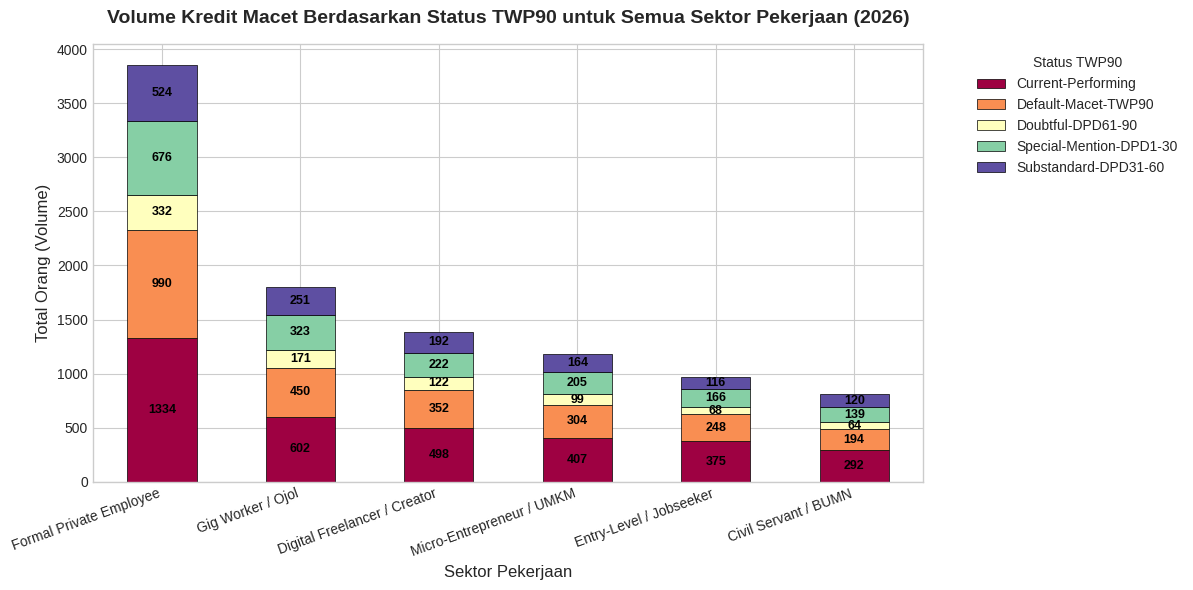

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
bars = volume_kredit_macet.plot(kind='bar', stacked=True, ax=ax, colormap='Spectral', edgecolor='black', linewidth=0.5)

plt.title('Volume Kredit Macet Berdasarkan Status TWP90 untuk Semua Sektor Pekerjaan (2026)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Sektor Pekerjaan', fontsize=12)
plt.ylabel('Total Orang (Volume)', fontsize=12)
plt.xticks(rotation=20, ha='right')
plt.legend(title='Status TWP90', bbox_to_anchor=(1.05, 1), loc='upper left')

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., p.get_y() + height / 2.),
                    ha='center', va='center',
                    xytext=(0, 0),
                    textcoords='offset points',
                    fontsize=9, fontweight='bold', color='black')

plt.tight_layout()
plt.show()

Analsis Beban Keuangan (Debt Service Ratio vs Default)

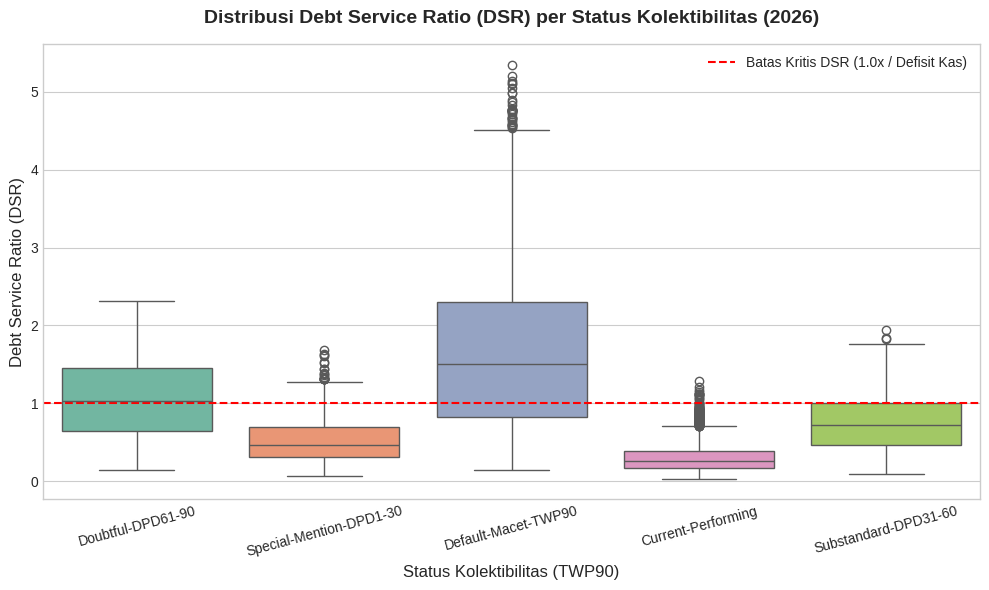

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='twp90_default_status', y='debt_service_ratio', data=df, palette='Set2', hue='twp90_default_status', legend=False)
plt.axhline(1.0, color='red', linestyle='--', linewidth=1.5, label='Batas Kritis DSR (1.0x / Defisit Kas)')
plt.title('Distribusi Debt Service Ratio (DSR) per Status Kolektibilitas (2026)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Status Kolektibilitas (TWP90)', fontsize=12)
plt.ylabel('Debt Service Ratio (DSR)', fontsize=12)
plt.xticks(rotation=15)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

Primary Root Causes

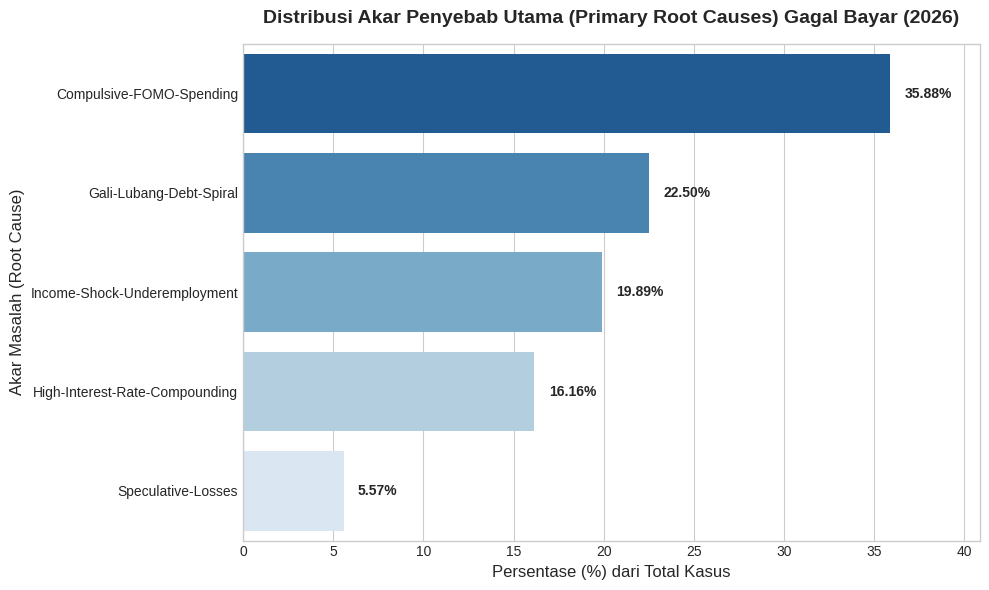

In [ ]:
plt.figure(figsize=(10, 6))

root_counts_pct = (df['primary_default_root_cause'].value_counts() / len(df)) * 100

ax = sns.barplot(x=root_counts_pct.values, y=root_counts_pct.index, palette='Blues_r', hue=root_counts_pct.index, legend=False)
plt.title('Distribusi Akar Penyebab Utama (Primary Root Causes) Gagal Bayar (2026)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Persentase (%) dari Total Kasus', fontsize=12)
plt.ylabel('Akar Masalah (Root Cause)', fontsize=12)

for p in ax.patches:
    width = p.get_width()
    ax.text(width + 0.8, p.get_y() + p.get_height()/2., f'{width:.2f}%',
            va='center', ha='left', fontsize=10, fontweight='bold')

plt.xlim(0, root_counts_pct.max() + 5)

plt.tight_layout()
plt.show()

In [ ]:
total_out = df['total_loan_outstanding_idr'].sum()
print(f"1. Total Outstanding: Rp {total_out:,.0f} (Sekitar {total_out/1e9:.2f} Miliar)")

1. Total Outstanding: Rp 99,015,900,000 (Sekitar 99.02 Miliar)


In [ ]:
status_pct = df['twp90_default_status'].value_counts(normalize=True) * 100
print(f"\n2 & 3. Persentase Status Kolektibilitas:\n{status_pct.round(2)}")


2 & 3. Persentase Status Kolektibilitas:
twp90_default_status
Current-Performing         35.08
Default-Macet-TWP90        25.38
Special-Mention-DPD1-30    17.31
Substandard-DPD31-60       13.67
Doubtful-DPD61-90           8.56
Name: proportion, dtype: float64


In [ ]:
job_default = pd.crosstab(df['employment_status'], df['twp90_default_status'], normalize='index') * 100
print(f"\n4. Proporsi Gagal Bayar per Sektor Pekerjaan:\n{job_default['Default-Macet-TWP90'].round(2)}")


4. Proporsi Gagal Bayar per Sektor Pekerjaan:
employment_status
Civil Servant / BUMN            23.98
Digital Freelancer / Creator    25.40
Entry-Level / Jobseeker         25.49
Formal Private Employee         25.67
Gig Worker / Ojol               25.04
Micro-Entrepreneur / UMKM       25.78
Name: Default-Macet-TWP90, dtype: float64


In [ ]:
dsr_avg = df.groupby('twp90_default_status')['debt_service_ratio'].mean()
print(f"\n5 & 6. Rata-rata DSR per Status:\n{dsr_avg.round(2)}")


5 & 6. Rata-rata DSR per Status:
twp90_default_status
Current-Performing         0.30
Default-Macet-TWP90        1.68
Doubtful-DPD61-90          1.05
Special-Mention-DPD1-30    0.53
Substandard-DPD31-60       0.76
Name: debt_service_ratio, dtype: float64


In [ ]:
util_avg = df.groupby('twp90_default_status')['credit_limit_utilization_ratio'].mean() * 100
print(f"\n7. Rata-rata Utilisasi Limit (%):\n{util_avg.round(2)}")


7. Rata-rata Utilisasi Limit (%):
twp90_default_status
Current-Performing         41.46
Default-Macet-TWP90        87.03
Doubtful-DPD61-90          66.47
Special-Mention-DPD1-30    51.99
Substandard-DPD31-60       58.70
Name: credit_limit_utilization_ratio, dtype: float64


In [ ]:
root_causes = df['primary_default_root_cause'].value_counts(normalize=True) * 100
print(f"\n8 & 9. Akar Masalah Gagal Bayar (%):\n{root_causes.round(2)}")


8 & 9. Akar Masalah Gagal Bayar (%):
primary_default_root_cause
Compulsive-FOMO-Spending          35.88
Gali-Lubang-Debt-Spiral           22.50
Income-Shock-Underemployment      19.89
High-Interest-Rate-Compounding    16.16
Speculative-Losses                 5.57
Name: proportion, dtype: float64


In [ ]:
filtered_df = df[(df['debt_service_ratio'] <= 0.8) & (df['num_active_lending_apps'] <= 3)]
simulated_default_rate = (filtered_df['twp90_default_status'] == 'Default-Macet-TWP90').mean() * 100
print(f"\n10. Simulasi Default Rate Setelah Filter DSR > 0.8 & Apps > 3: {simulated_default_rate:.2f}% (Drastis turun karena risiko tinggi telah disaring)")


10. Simulasi Default Rate Setelah Filter DSR > 0.8 & Apps > 3: 0.06% (Drastis turun karena risiko tinggi telah disaring)


In [ ]:
def assign_risk_tier(row):
    if row['debt_service_ratio'] > 0.8 or row['credit_limit_utilization_ratio'] > 0.8 or row['num_active_lending_apps'] >= 5:
        return 'Tier 3: High Risk (Critical)'
    elif row['debt_service_ratio'] > 0.5 or row['credit_limit_utilization_ratio'] > 0.6 or row['num_active_lending_apps'] >= 3:
        return 'Tier 2: Medium Risk (Watchlist)'
    else:
        return 'Tier 1: Low Risk (Safe)'

df['risk_tier'] = df.apply(assign_risk_tier, axis=1)

print("--- Hasil Customer Risk Segmentation ---")
print(df['risk_tier'].value_counts(normalize=True) * 100)

--- Hasil Customer Risk Segmentation ---
risk_tier
Tier 3: High Risk (Critical)       57.15
Tier 2: Medium Risk (Watchlist)    30.59
Tier 1: Low Risk (Safe)            12.26
Name: proportion, dtype: float64
